# Titanic Survivor Prediction

In this notebook we will prepare the Titanic data for the prediction model
We will first check the data and then fill the missing values using similar passengers

In [171]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [172]:
#stander imports
import os
# Third Party imports
import numpy as np
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
#local imports

| **Variable** | **Definition** | **Key** |
|---|---|---|
| survival | Survival | 0 = No, 1 = Yes |
| pclass | Ticket class | 1 = 1st, 2 = 2nd, 3 = 3rd |
| sex | Sex | |
| Age | Age in years | |
| sibsp | # of siblings / spouses aboard the Titanic | |
| parch | # of parents / children aboard the Titanic | |
| ticket | Ticket number | |
| fare | Passenger fare | |
| cabin | Cabin number | |
| embarked | Port of Embarkation | C = Cherbourg, Q = Queenstown, S = Southampton |

## Loading the datasets

We will load the train and test data first
After we display them we can check the columns and the structure of both datasets

In [173]:
train_data = pd.read_csv('train.csv')

test_data = pd.read_csv('test.csv')

display(train_data)
display(test_data)



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


## Separating the target and combining the passenger records

We will keep the Survived column separate because this is the value we want to predict
Then we combine the train and test data so we can update the missing values in the same way

In [174]:
survived = train_data['Survived']
train_data = train_data.drop(['Survived'], axis=1)
display(train_data)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
886,887,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


## Inspecting missing values

Before we update the missing values we will check how many there are in every column
This will help us choose a different way to fill each column

In [175]:
train_index = train_data['PassengerId']
test_index = test_data['PassengerId']
combined_data = pd.concat([train_data, test_data]).reset_index(drop=True)

display(combined_data)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
1305,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
1306,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
1307,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


A lot of missing values, let's check how many

In [176]:
combined_data.isnull().sum()

PassengerId       0
Pclass            0
Name              0
Sex               0
Age             263
SibSp             0
Parch             0
Ticket            0
Fare              1
Cabin          1014
Embarked          2
dtype: int64

We will Update the missing values in the future for each section
By getting an estimated value .

For the age we will first check if the Pclass has any correlation to the age
After we run it we will see that the median showsthat older people tend to purchuse higher class tickets

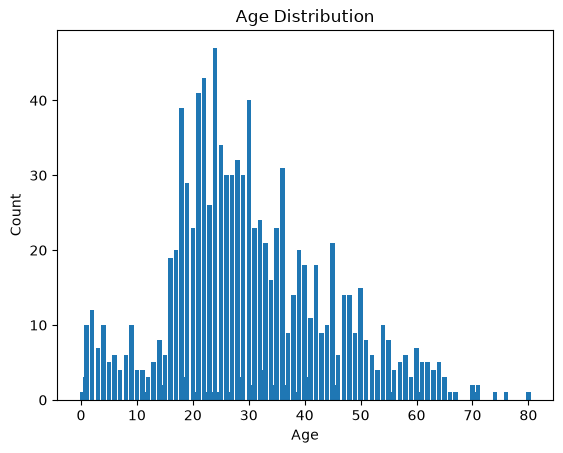

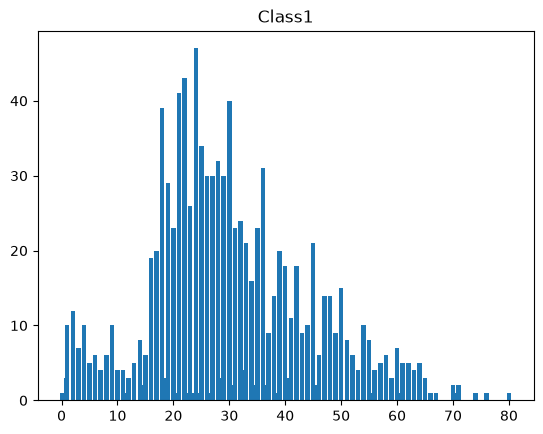

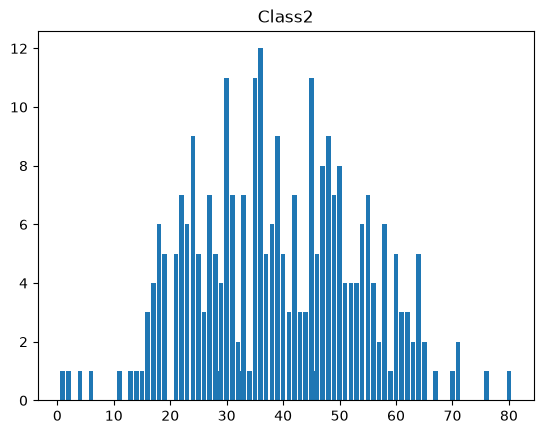

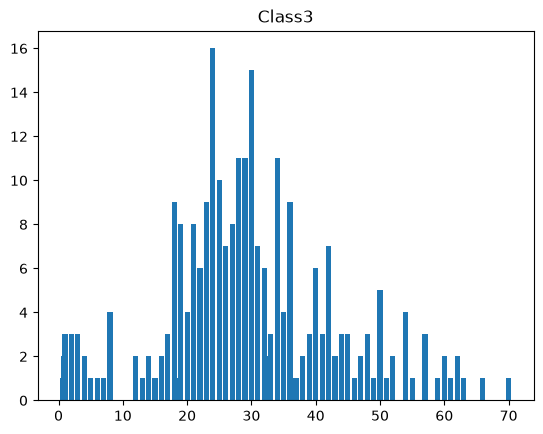

         Age
Pclass      
1       39.0
2       29.0
3       24.0


In [177]:
y= combined_data['Age'].value_counts()
x= y.index.values

plt.Figure(figsize=(10, 5))
plt.bar(x, y)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

class_age = combined_data[['Pclass','Age']]

for i in range(1,4):
    plt.Figure(figsize=(10, 5))
    plt.bar(x, y)
    plt.title('Class' + str(i) )
    y=class_age[class_age['Pclass']==i]['Age'].value_counts()
    x= y.index.values
    plt.show()

median = class_age.groupby('Pclass').median()
print(median)

In [178]:
#We combine the data and fill the missing values of Age with the median of the corresponding Pclass
for i in range(3):
  idx = np.where((combined_data['Pclass'] == i+1) & (combined_data['Age'].isnull()))[0]
  combined_data.loc[idx, 'Age'] = median.values[i][0]
display(combined_data)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,3,"Spector, Mr. Woolf",male,24.0,0,0,A.5. 3236,8.0500,NaN,S
1305,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
1306,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
1307,1308,3,"Ware, Mr. Frederick",male,24.0,0,0,359309,8.0500,NaN,S


## Imputing the fare

For the missing fare we will check passengers from the same Pclass and Embarked group
After we find the median fare of this group we will use it to fill the missing value

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1043,1044,3,"Storey, Mr. Thomas",male,60.5,0,0,3701,NaN,NaN,S


8.05


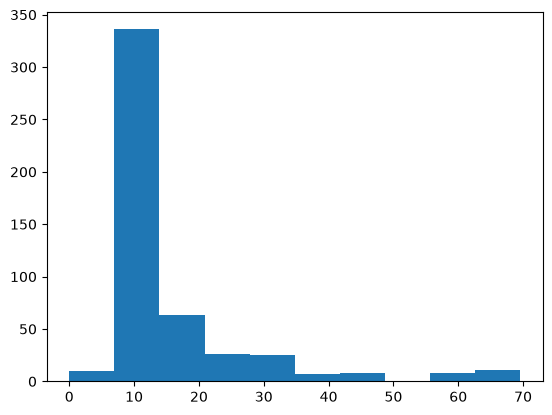

In [179]:
display(combined_data[combined_data['Fare'].isnull()])

sim_fare = combined_data[(combined_data['Pclass']==3) & (combined_data['Embarked']=='S')]['Fare']
plt.hist(sim_fare)
plt.plot()
print(sim_fare.median())

combined_data['Fare'] = combined_data['Fare'].fillna(sim_fare.median())

## Imputing the embarkation port

For the missing Embarked value we will check passengers with similar Pclass and Fare
The most common embarkation point will be used to fill the missing value

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
61,62,1,"Icard, Miss. Amelie",female,38.0,0,0,113572,80.0,B28,NaN
829,830,1,"Stone, Mrs. George Nelson (Martha Evelyn)",female,62.0,0,0,113572,80.0,B28,NaN


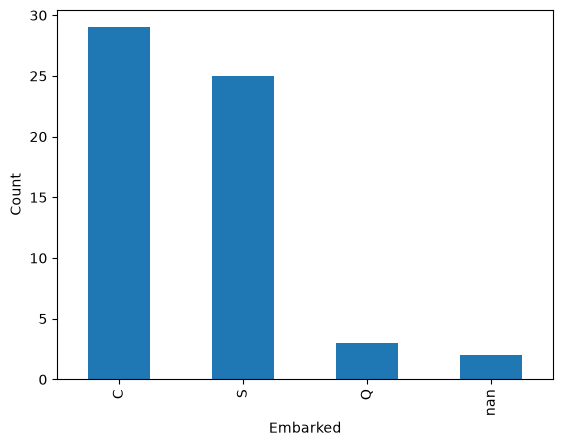

In [180]:
display(combined_data[combined_data['Embarked'].isnull()])

sim_embarked = combined_data[(combined_data['Pclass']==1) & (combined_data['Fare']>=70) & (combined_data['Fare']<=90)]['Embarked']
sim_embarked.value_counts(dropna=False).plot.bar()

plt.xlabel("Embarked")
plt.ylabel("Count")
plt.show()

combined_data['Embarked'] = combined_data['Embarked'].fillna('C')

## Simplifying the cabin information

Most passengers do not have a Cabin value so we will fill the missing values with M
Then we will keep only the first letter of the cabin because it shows the deck
The T value will also be changed to M because it appears only once

In [181]:
combined_data['Cabin'] = combined_data['Cabin'].fillna('M')
combined_data['Cabin'] = combined_data['Cabin'].str[0]

print(combined_data['Cabin'].value_counts())

idx = np.where(combined_data['Cabin'] == 'T')[0]
combined_data.loc[idx, 'Cabin'] = 'M'

Cabin
M    1014
C      94
B      65
D      46
E      41
A      22
F      21
G       5
T       1
Name: count, dtype: int64


## Checking the completed preprocessing

After we update all the missing values we will display the data again
Finally we will check if there are any missing values left

In [182]:
display(combined_data)

print(combined_data.isnull().sum())

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,M,S
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,M,S
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C,S
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,M,S
...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,3,"Spector, Mr. Woolf",male,24.0,0,0,A.5. 3236,8.0500,M,S
1305,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C,C
1306,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,M,S
1307,1308,3,"Ware, Mr. Frederick",male,24.0,0,0,359309,8.0500,M,S


PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64


## Checking the feature values

We will check how many different values each column has
This will help us see which columns can be useful for the model

In [183]:
print(combined_data.nunique())

print(combined_data['Pclass'].unique())

PassengerId    1309
Pclass            3
Name           1307
Sex               2
Age              98
SibSp             7
Parch             8
Ticket          929
Fare            281
Cabin             8
Embarked          3
dtype: int64
[3 1 2]


## Creating a title feature

We will split the Name column to find the last name and the title of each passenger
After that we will combine the less common titles into bigger groups

In [184]:
print(combined_data['Pclass'].unique())

names = combined_data['Name']

last_names = []
titles = []
first_names = []

for name in names:
    if ',' not in name:
        last_names.append('')
    else:
        last, name  = name.split(',', 1)
        last_names.append(last.strip())
    if '.' not in name:
        titles.append('')
    else:
        title, first = name.split('.', 1)
        titles.append(title.strip())
        first_names.append(first)

last_names = np.array(last_names)
titles = np.array(titles)
first_names = np.array(first_names)

idx= np.where(np.isin(titles,['Capt', 'Col','Major']))
titles[idx] = 'Military'

idx= np.where(np.isin(titles,['Don', 'Dona','Jonkheer', 'Lady','Sir','Master','the Countess']))
titles[idx] = 'Nobility'

idx= np.where(np.isin(titles,['Miss', 'Mlle','Ms']))
titles[idx] = 'Ms'

idx= np.where(np.isin(titles,['Mirs', 'Mme']))
titles[idx] = 'Mrs'

print(np.unique(titles, return_counts=True))

combined_data['Title'] = titles

display(combined_data)

[3 1 2]
(array(['Dr', 'Military', 'Mr', 'Mrs', 'Ms', 'Nobility', 'Rev'],
      dtype='<U12'), array([  8,   7, 757, 198, 264,  67,   8]))


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,M,S,Mr
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C,Mrs
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,M,S,Ms
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C,S,Mrs
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,M,S,Mr
...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,3,"Spector, Mr. Woolf",male,24.0,0,0,A.5. 3236,8.0500,M,S,Mr
1305,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C,C,Nobility
1306,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,M,S,Mr
1307,1308,3,"Ware, Mr. Frederick",male,24.0,0,0,359309,8.0500,M,S,Mr


## Creating age groups

We will check the minimum and maximum age first
Then we will split the passengers into age groups because the model can use these groups as categorical information

In [185]:
print(combined_data['Age'].min(), combined_data['Age'].max())

bins = np.array([0, 10, 20, 30, 40, 50, 60, 70, 80])

combined_data['Age_Bin'] = pd.cut(combined_data['Age'], bins)

display(combined_data)

0.17 80.0


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,Age_Bin
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,M,S,Mr,"(20, 30]"
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C,Mrs,"(30, 40]"
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,M,S,Ms,"(20, 30]"
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C,S,Mrs,"(30, 40]"
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,M,S,Mr,"(30, 40]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,3,"Spector, Mr. Woolf",male,24.0,0,0,A.5. 3236,8.0500,M,S,Mr,"(20, 30]"
1305,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C,C,Nobility,"(30, 40]"
1306,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,M,S,Mr,"(30, 40]"
1307,1308,3,"Ware, Mr. Frederick",male,24.0,0,0,359309,8.0500,M,S,Mr,"(20, 30]"


## Counting passengers per ticket

We will count how many passengers have the same ticket
This can show us how many people were travelling together

In [186]:
ticket_dict = dict(combined_data['Ticket'].value_counts())

combined_data['Ticket_Count'] = combined_data['Ticket'].map(ticket_dict)

display(combined_data)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,Age_Bin,Ticket_Count
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,M,S,Mr,"(20, 30]",1
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C,Mrs,"(30, 40]",2
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,M,S,Ms,"(20, 30]",1
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C,S,Mrs,"(30, 40]",2
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,M,S,Mr,"(30, 40]",1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,3,"Spector, Mr. Woolf",male,24.0,0,0,A.5. 3236,8.0500,M,S,Mr,"(20, 30]",1
1305,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C,C,Nobility,"(30, 40]",3
1306,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,M,S,Mr,"(30, 40]",1
1307,1308,3,"Ware, Mr. Frederick",male,24.0,0,0,359309,8.0500,M,S,Mr,"(20, 30]",1


## Creating the fare per ticket feature

We will divide the fare by the number of passengers with the same ticket
After that we will also create groups for the fare per ticket

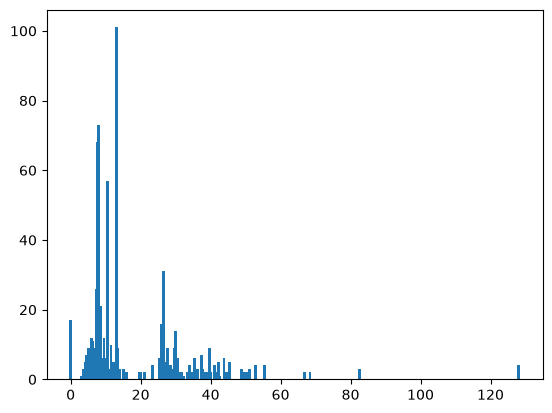

0.0 128.0823


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,Age_Bin,Ticket_Count,Fare_per_Ticket,Fare_per_Ticket_Bin
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,M,S,Mr,"(20, 30]",1,7.250000,"(0, 20]"
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C,Mrs,"(30, 40]",2,35.641650,"(20, 40]"
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,M,S,Ms,"(20, 30]",1,7.925000,"(0, 20]"
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C,S,Mrs,"(30, 40]",2,26.550000,"(20, 40]"
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,M,S,Mr,"(30, 40]",1,8.050000,"(0, 20]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,3,"Spector, Mr. Woolf",male,24.0,0,0,A.5. 3236,8.0500,M,S,Mr,"(20, 30]",1,8.050000,"(0, 20]"
1305,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C,C,Nobility,"(30, 40]",3,36.300000,"(20, 40]"
1306,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,M,S,Mr,"(30, 40]",1,7.250000,"(0, 20]"
1307,1308,3,"Ware, Mr. Frederick",male,24.0,0,0,359309,8.0500,M,S,Mr,"(20, 30]",1,8.050000,"(0, 20]"


In [187]:
combined_data['Fare_per_Ticket'] = combined_data['Fare'] / combined_data['Ticket_Count']

plt.bar(combined_data['Fare_per_Ticket'].value_counts().index, combined_data['Fare_per_Ticket'].value_counts())
plt.show()


print(combined_data['Fare_per_Ticket'].min(), combined_data['Fare_per_Ticket'].max())

bins = np.array([0,20,40,60,80,150])
combined_data['Fare_per_Ticket_Bin'] = pd.cut(combined_data['Fare_per_Ticket'], bins)

display(combined_data)

## Creating the family size feature

We will add the number of siblings, spouses, parents and children
The plus one is for the passenger because the other columns only count the family members

In [188]:
combined_data['Number_of_Family'] = combined_data['SibSp'] + combined_data['Parch'] +1

display(combined_data)

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,Age_Bin,Ticket_Count,Fare_per_Ticket,Fare_per_Ticket_Bin,Number_of_Family
0,1,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,M,S,Mr,"(20, 30]",1,7.250000,"(0, 20]",2
1,2,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C,Mrs,"(30, 40]",2,35.641650,"(20, 40]",2
2,3,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,M,S,Ms,"(20, 30]",1,7.925000,"(0, 20]",1
3,4,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C,S,Mrs,"(30, 40]",2,26.550000,"(20, 40]",2
4,5,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,M,S,Mr,"(30, 40]",1,8.050000,"(0, 20]",1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,3,"Spector, Mr. Woolf",male,24.0,0,0,A.5. 3236,8.0500,M,S,Mr,"(20, 30]",1,8.050000,"(0, 20]",1
1305,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C,C,Nobility,"(30, 40]",3,36.300000,"(20, 40]",1
1306,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,M,S,Mr,"(30, 40]",1,7.250000,"(0, 20]",1
1307,1308,3,"Ware, Mr. Frederick",male,24.0,0,0,359309,8.0500,M,S,Mr,"(20, 30]",1,8.050000,"(0, 20]",1


## Removing the original features

We will remove the columns that we used to create the new features
The model will use the simpler features instead of the original text and numeric columns

In [189]:
combined_data.drop(['Name', 'Age', 'Ticket', 'Fare', 'Ticket_Count', 'Fare_per_Ticket'],axis=1, inplace=True)  

display(combined_data)

,PassengerId,Pclass,Sex,SibSp,Parch,Cabin,Embarked,Title,Age_Bin,Fare_per_Ticket_Bin,Number_of_Family
0,1,3,male,1,0,M,S,Mr,"(20, 30]","(0, 20]",2
1,2,1,female,1,0,C,C,Mrs,"(30, 40]","(20, 40]",2
2,3,3,female,0,0,M,S,Ms,"(20, 30]","(0, 20]",1
3,4,1,female,1,0,C,S,Mrs,"(30, 40]","(20, 40]",2
4,5,3,male,0,0,M,S,Mr,"(30, 40]","(0, 20]",1
...,...,...,...,...,...,...,...,...,...,...,...
1304,1305,3,male,0,0,M,S,Mr,"(20, 30]","(0, 20]",1
1305,1306,1,female,0,0,C,C,Nobility,"(30, 40]","(20, 40]",1
1306,1307,3,male,0,0,M,S,Mr,"(30, 40]","(0, 20]",1
1307,1308,3,male,0,0,M,S,Mr,"(20, 30]","(0, 20]",1


## Checking the final features

Finally we will check how many different values are left in each column
This will help us see the final data before we prepare it for the Random Forest

In [190]:
print(combined_data.nunique())

PassengerId            1309
Pclass                    3
Sex                       2
SibSp                     7
Parch                     8
Cabin                     8
Embarked                  3
Title                     7
Age_Bin                   8
Fare_per_Ticket_Bin       5
Number_of_Family          9
dtype: int64


## Importing the model tools

We will import the Random Forest model and the tools for splitting, scaling and checking the data
After that we can prepare the data for training

In [191]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.metrics import accuracy_score 
from sklearn.preprocessing import MinMaxScaler


## Setting the passenger index

We will use PassengerId as the index so we can separate the original train data from the test data later

In [192]:
combined_data.set_index('PassengerId', inplace=True)

display(combined_data)

,Pclass,Sex,SibSp,Parch,Cabin,Embarked,Title,Age_Bin,Fare_per_Ticket_Bin,Number_of_Family
PassengerId,,,,,,,,,,
1,3,male,1,0,M,S,Mr,"(20, 30]","(0, 20]",2
2,1,female,1,0,C,C,Mrs,"(30, 40]","(20, 40]",2
3,3,female,0,0,M,S,Ms,"(20, 30]","(0, 20]",1
4,1,female,1,0,C,S,Mrs,"(30, 40]","(20, 40]",2
5,3,male,0,0,M,S,Mr,"(30, 40]","(0, 20]",1
...,...,...,...,...,...,...,...,...,...,...
1305,3,male,0,0,M,S,Mr,"(20, 30]","(0, 20]",1
1306,1,female,0,0,C,C,Nobility,"(30, 40]","(20, 40]",1
1307,3,male,0,0,M,S,Mr,"(30, 40]","(0, 20]",1


## Encoding the categorical values

We will change the values to strings and then encode them as numbers
This is needed because the Random Forest model cannot use text values directly

In [193]:
from sklearn.preprocessing import LabelEncoder

label_enc= combined_data.copy()
label_enc = label_enc.astype(str)

label_enc = label_enc.apply(LabelEncoder().fit_transform)

display(label_enc)


,Pclass,Sex,SibSp,Parch,Cabin,Embarked,Title,Age_Bin,Fare_per_Ticket_Bin,Number_of_Family
PassengerId,,,,,,,,,,
1,2,1,1,0,7,2,2,2,0,2
2,0,0,1,0,2,0,3,3,1,2
3,2,0,0,0,7,2,4,2,0,0
4,0,0,1,0,2,2,3,3,1,2
5,2,1,0,0,7,2,2,3,0,0
...,...,...,...,...,...,...,...,...,...,...
1305,2,1,0,0,7,2,2,2,0,0
1306,0,0,0,0,2,0,5,3,1,0
1307,2,1,0,0,7,2,2,3,0,0


## Creating one-hot features

We will create separate columns for Sex, Embarked and Title
This will make the categorical values easier for the model to use

In [194]:
one_hot = label_enc.copy()

one_hot = pd.get_dummies(one_hot, columns=['Sex', 'Embarked', 'Title'])

display(one_hot)

,Pclass,SibSp,Parch,Cabin,Age_Bin,Fare_per_Ticket_Bin,Number_of_Family,Sex_0,Sex_1,Embarked_0,Embarked_1,Embarked_2,Title_0,Title_1,Title_2,Title_3,Title_4,Title_5,Title_6
PassengerId,,,,,,,,,,,,,,,,,,,
1,2,1,0,7,2,0,2,False,True,False,False,True,False,False,True,False,False,False,False
2,0,1,0,2,3,1,2,True,False,True,False,False,False,False,False,True,False,False,False
3,2,0,0,7,2,0,0,True,False,False,False,True,False,False,False,False,True,False,False
4,0,1,0,2,3,1,2,True,False,False,False,True,False,False,False,True,False,False,False
5,2,0,0,7,3,0,0,False,True,False,False,True,False,False,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1305,2,0,0,7,2,0,0,False,True,False,False,True,False,False,True,False,False,False,False
1306,0,0,0,2,3,1,0,True,False,True,False,False,False,False,False,False,False,True,False
1307,2,0,0,7,3,0,0,False,True,False,False,True,False,False,True,False,False,False,False


## Preparing the training data

We will separate the train rows and the Survived values
Then we will scale the features and split the data into training and test groups

In [195]:
X = one_hot.loc[train_index].values 
y = survived.values  

scaler = MinMaxScaler()
scaler.fit(X)
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=0)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(712, 19) (179, 19) (712,) (179,)


## Training the first Random Forest

We will first train a Random Forest with the default parameters
After that we can use its accuracy as a first result

In [196]:
clf = RandomForestClassifier(random_state=0)
clf.fit(X_train, y_train).score(X_test, y_test)

0.7932960893854749

## Searching for better parameters

We will create different values for the Random Forest parameters
RandomizedSearchCV will test random combinations and find a better starting point

In [197]:
params = {
    'criterion': ['gini', 'entropy'],
    'n_estimators': [20, 50, 100, 200, 300, 400, 500, 800, 1000],
    'max_depth': np.arange(3, 50),
    'min_samples_split': np.arange(1, 1000),
    'max_features': ['sqrt', 'log2'],
    'max_samples': np.linspace(0.1, 0.9, 10)
}

rand_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=0),
    params,
    scoring='accuracy',
    random_state=0,
    cv=5
)

rand_search.fit(X_train, y_train)

rand_params = rand_search.best_params_
print(rand_params,'\n')
print('Train Accuracy:', rand_search.best_score_)
preds = rand_search.predict(X_test)
print('Test Accuracy:', accuracy_score(y_test, preds))

{'n_estimators': 200, 'min_samples_split': np.int64(16), 'max_samples': np.float64(0.6333333333333333), 'max_features': 'sqrt', 'max_depth': np.int64(49), 'criterion': 'gini'} 

Train Accuracy: 0.8286417807544568
Test Accuracy: 0.8268156424581006


## Checking the best parameters

We will create a smaller range around the parameters found by the randomized search
Then GridSearchCV will check all the combinations in this smaller range

In [205]:
n_estimators = np.linspace(rand_params['n_estimators']-10, rand_params['n_estimators']+10, 3).astype(int)

min_samples_split = np.arange(rand_params['min_samples_split']-3, rand_params['min_samples_split']+3, 3).astype(int)

max_samples = np.arange(rand_params['max_samples']-0.5, rand_params['max_samples']+0.5, 6)

max_depth = np.arange(rand_params['max_depth']-5, rand_params['max_depth']+5).astype(int)

params = {
    'criterion': [rand_params['criterion']],
    'n_estimators': n_estimators,
    'max_depth': max_depth,
    'min_samples_split': min_samples_split,
    'max_features': [rand_params['max_features']],
    'max_samples': max_samples
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=0),
    params,
    scoring='accuracy',
    cv=5
)

grid_search.fit(X_train, y_train)

gr_params = grid_search.best_params_
print(gr_params,'\n')
print('Train Accuracy:', grid_search.best_score_)
preds = grid_search.predict(X_test)
print('Test Accuracy:', accuracy_score(y_test, preds))

{'criterion': 'gini', 'max_depth': np.int64(44), 'max_features': 'sqrt', 'max_samples': np.float64(0.1333333333333333), 'min_samples_split': np.int64(13), 'n_estimators': np.int64(210)} 

Train Accuracy: 0.807613513247316
Test Accuracy: 0.8212290502793296
